# ADY201m · Notebook Pipeline v1.1 — RQ1, RQ2, RQ3

**Phân tích dữ liệu giáo dục và hệ thống cảnh báo sớm (Early-Warning System)**

Notebook này chạy lại toàn bộ pipeline `ADY201m_RQ1_RQ2_RQ3_PIPELINE.py` (v1.1) từ dữ liệu đến kết quả, mỗi bước có ô Markdown giải thích mục tiêu, cách thực hiện và biện luận. Nội dung chỉ gồm ba câu hỏi nghiên cứu:

1. **RQ1:** *Which pre-final assessment components are most strongly associated with an unsuccessful outcome?*
2. **RQ2:** *Which of five algorithms (Decision Tree, Random Forest, XGBoost, LightGBM, and CatBoost) performs best for the early-warning task?*
3. **RQ3:** *Does SMOTE, together with F2-based threshold tuning, improve the recall-oriented performance of the selected model?*

**Quy ước:** `TARGET = 1` là **không đạt** (*unsuccessful*), `TARGET = 0` là **đạt**. Chỉ dùng điểm **trước kỳ thi cuối kỳ**; `FINAL EXAM`, `TOTAL`, `STATUS` không được đưa vào đầu vào để tránh *data leakage*.

**Dữ liệu:** bộ dữ liệu gộp đã làm sạch `ADY201m_combined_cleaned.csv` (124.791 dòng, 18 `SOURCE_FILE`; 110.704 dòng dùng để mô hình hóa) được **nhúng sẵn** trong notebook, nên không cần tải thêm tệp. Notebook in SHA-256 của dữ liệu để truy vết. Dữ liệu này không thay thế pipeline làm sạch dữ liệu thô.

**Tái lập kết quả:** `random_state = 42` và các tham số mô hình cố định. Kết quả của các mô hình cây phụ thuộc phiên bản thư viện, nên ô thiết lập ở dưới ghim đúng phiên bản của lần chạy tham chiếu, và ô cuối cùng (mục 14) đối chiếu kết quả của lần chạy này với kết quả tham chiếu. Nếu khác phiên bản/phần cứng, chênh lệch nhỏ có thể xuất hiện; khi đó hãy xem mục 14.

## 0. Chuẩn bị môi trường và ghim phiên bản

**Giải thích:** Ô dưới kiểm tra phiên bản của năm thư viện ảnh hưởng trực tiếp đến kết quả huấn luyện (`scikit-learn`, `imbalanced-learn`, `xgboost`, `lightgbm`, `catboost`) so với phiên bản của lần chạy tham chiếu. Trên Google Colab, notebook tự cài đúng phiên bản nếu khác. Trên máy cá nhân, notebook **không tự thay đổi môi trường**; nếu có khác biệt, nó in sẵn lệnh `pip install` (nên chạy trong môi trường ảo) hoặc có thể đặt `AUTO_INSTALL = True`.

**Biện luận:** Cùng dữ liệu, cùng `random_state` nhưng khác phiên bản thư viện có thể cho mô hình tốt nhất khác nhau (Random Forest đặc biệt nhạy). Vì vậy kết quả chỉ được xem là tái lập khi phiên bản khớp, hoặc khi mục 14 xác nhận kết quả nằm trong dung sai. `scikit-learn` từ 1.4 trở lên là yêu cầu để Decision Tree/Random Forest xử lý `NaN` trực tiếp.

In [1]:
# 0. Kiểm tra / ghim phiên bản thư viện
import sys, subprocess, platform, json
from importlib.metadata import version, PackageNotFoundError

PINNED = {"scikit-learn": "1.9.1", "imbalanced-learn": "0.14.2", "xgboost": "3.4.1", "lightgbm": "4.7.0", "catboost": "1.2.10"}
REFERENCE_PYTHON = "3.14.5"
IN_COLAB = 'google.colab' in sys.modules
AUTO_INSTALL = IN_COLAB   # đặt True để tự cài đúng phiên bản trên máy cá nhân (nên dùng môi trường ảo)

def _ver(pkg):
    try: return version(pkg)
    except PackageNotFoundError: return None

def _mismatch():
    return {p: v for p, v in PINNED.items() if _ver(p) != v}

bad = _mismatch()
if bad and AUTO_INSTALL:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *[f'{p}=={v}' for p, v in bad.items()]])
    print('Đã cài đúng phiên bản. Nếu có thông báo yêu cầu khởi động lại, hãy khởi động lại phiên (Restart) rồi chạy lại từ đầu.')
    bad = _mismatch()

print(f'Python {platform.python_version()} (tham chiếu: {REFERENCE_PYTHON})')
for p, v in PINNED.items():
    print(f'  {p:18s} cần {v:8s} | đang dùng {_ver(p) or "CHƯA CÀI"}')
if bad:
    print('\nCẢNH BÁO: phiên bản khác lần chạy tham chiếu; kết quả có thể lệch nhẹ (xem mục 14). Để khớp, chạy:')
    print('  pip install ' + ' '.join(f'{p}=={v}' for p, v in PINNED.items()))
else:
    print('\nPhiên bản thư viện khớp lần chạy tham chiếu.')

Python 3.13.18 (tham chiếu: 3.14.5)
  scikit-learn       cần 1.9.1    | đang dùng 1.9.1
  imbalanced-learn   cần 0.14.2   | đang dùng 0.14.2
  xgboost            cần 3.4.1    | đang dùng 3.4.1
  lightgbm           cần 4.7.0    | đang dùng 4.7.0
  catboost           cần 1.2.10   | đang dùng 1.2.10

Phiên bản thư viện khớp lần chạy tham chiếu.


## 1. Import thư viện và cấu hình tái lập

**Giải thích:** Giữ nguyên các thư viện và cấu hình cốt lõi của script v1.1: `random_state=42`, chia dữ liệu theo nhóm `SOURCE_FILE + CODE`, và dùng toàn bộ dữ liệu (`QUICK_CHECK=False`).

**Biện luận:** Chế độ `quick-check` chỉ dùng thử lệnh, không dùng để báo cáo kết quả. So sánh công bằng cần dùng thiết lập chạy FULL và không đổi ngưỡng/model theo tập test.

In [2]:
from pathlib import Path
import json
import warnings
import sys
import platform
import argparse
from datetime import datetime

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    fbeta_score, roc_auc_score, average_precision_score,
    confusion_matrix,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SCRIPT_VERSION = "ADY201m_PIPELINE_CHI_RQ1_RQ2_RQ3 v1.1 (no imputation; goc: GROUPED v1.0.0)"
SCRIPT_DIR = Path.cwd()
QUICK_CHECK = False  # FULL: dung toan bo du lieu, dung thong so v1.1
RANDOM_STATE = 42
USE_GROUP_SPLIT = True
MIN_RQ1_N_WITHIN_FILE = 30
GROUP_KEY_DEFINITION = "SOURCE_FILE + '___' + CODE"
OUT_DIR = SCRIPT_DIR / "KET_QUA_CHAY_NOTEBOOK_V1_1"
OUT_DIR.mkdir(exist_ok=True, parents=True)
print(f'Chế độ: FULL | Kết quả: {OUT_DIR.resolve()}')


Chế độ: FULL | Kết quả: /tmp/claude-0/-home-claude/86b98766-2cfc-5df3-accc-f3ea7128e976/scratchpad/nbrun/KET_QUA_CHAY_NOTEBOOK_V1_1


## 2. Chuẩn bị bộ CSV đã làm sạch

**Giải thích:** Dữ liệu đã làm sạch được nén và nhúng vào Notebook, nên bạn **không cần upload thêm file** khi chạy trên Colab. Ô dữ liệu được thu gọn để không xuất hiện hàng nghìn dòng ký tự như notebook cũ. Dữ liệu sau giải nén được lưu tại `DU_LIEU/ADY201m_combined_cleaned.csv`, đúng đường dẫn mà script v1.1 yêu cầu.

**Biện luận:** Cách đóng gói này giúp notebook chạy độc lập nhưng **không thay thế pipeline cleaning dữ liệu thô**. Để truy vết, notebook in SHA-256 của CSV được sử dụng.

In [3]:
#@title Nạp dữ liệu tích hợp (nhấn để mở mã dữ liệu đã nén) { display-mode: "form" }
import base64, zlib, hashlib
DATA_DIR = SCRIPT_DIR / "DU_LIEU"
DATA_DIR.mkdir(exist_ok=True, parents=True)
combined_path = DATA_DIR / "ADY201m_combined_cleaned.csv"
BUNDLED_CSV_B64 = "..."
raw_bytes = zlib.decompress(base64.b64decode(BUNDLED_CSV_B64))
expected_sha256 = "bf34a36b77f9b70647ea0cacc04c266cb119a2f3376c9683bebeffd578b2517b"
assert hashlib.sha256(raw_bytes).hexdigest() == expected_sha256, "Dữ liệu nhúng không đúng checksum"
if not combined_path.exists() or hashlib.sha256(combined_path.read_bytes()).hexdigest() != expected_sha256:
    combined_path.write_bytes(raw_bytes)
del raw_bytes, BUNDLED_CSV_B64
print('Đã chuẩn bị:', combined_path, '\nSHA-256:', expected_sha256)


Đã chuẩn bị: /tmp/claude-0/-home-claude/86b98766-2cfc-5df3-accc-f3ea7128e976/scratchpad/nbrun/DU_LIEU/ADY201m_combined_cleaned.csv 
SHA-256: bf34a36b77f9b70647ea0cacc04c266cb119a2f3376c9683bebeffd578b2517b


## 3. Data Understanding: đọc và kiểm tra dữ liệu

**Giải thích:** Đọc CSV và kiểm tra bốn cột bắt buộc: `TARGET`, `CODE`, `SOURCE_FILE`, `HAS_PREFINAL`. Chỉ dùng các dòng có điểm **trước final** và nhãn 0/1. Tập biến được giới hạn ở 21 cột điểm tiền final đã định nghĩa trong v1.1.

**Biện luận:** Loại `TOTAL` và điểm `FINAL EXAM` khỏi đặc trưng để tránh **rò rỉ thông tin tương lai**. `HAS_PREFINAL` bảo đảm câu hỏi là cảnh báo sớm chứ không phải dự đoán sau khi kết thúc môn học.

In [4]:
# 1. LOAD DATA - original combined cleaned CSV
# ------------------------------------------------------------
combined_path = SCRIPT_DIR / "DU_LIEU" / "ADY201m_combined_cleaned.csv"
if not combined_path.is_file():
    raise FileNotFoundError(f"Khong tim thay du lieu goc: {combined_path}")

df = pd.read_csv(combined_path, low_memory=False)
print(f"[OK] Loaded canonical combined CSV: {combined_path}")

# ------------------------------------------------------------
# 2. CORE DATA AUDIT
# ------------------------------------------------------------
required = {"TARGET", "CODE", "SOURCE_FILE", "HAS_PREFINAL"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {sorted(missing_required)}")

FEATURES = [
    "LABS-10",
    "ASSIGNMENTS-10",
    "PROGRESS TESTS-30",
    "ASSIGNMENTS-30",
    "EXERCISES-30",
    "QUIZ-20",
    "ASSIGNMENTS-20",
    "PRACTICAL EXAM-30",
    "PROGRESS TESTS-20",
    "PROGRESS TESTS-10",
    "QUIZ-10",
    "LABS-15",
    "PRACTICAL EXAM-25",
    "PRESENTATION-20",
    "ACTIVE LEARNING-10",
    "PROJECT-30",
    "EXERCISES-10",
    "LABS-20",
    "PRACTICAL EXAM-40",
    "WORKSHOP-10",
    "PRACTICAL EXAM-20",
]
FEATURES = [c for c in FEATURES if c in df.columns]

for bad in ["TOTAL", "FINAL EXAM-30", "FINAL EXAM-40"]:
    if bad in FEATURES:
        raise RuntimeError(f"Leakage column included in feature list: {bad}")

model_df = df[(df["HAS_PREFINAL"] == True) & df["TARGET"].isin([0, 1])].copy()
model_df["TARGET"] = model_df["TARGET"].astype(int)
if QUICK_CHECK:
    # Stratified sample only for execution testing. Final reported results
    # must be generated in full mode (without --quick-check).
    if len(model_df) > 6000:
        _, model_df = train_test_split(
            model_df, test_size=6000,
            stratify=model_df["TARGET"], random_state=RANDOM_STATE
        )
    model_df = model_df.sort_index().copy()


print("\n=== DATA AUDIT ===")
print(f"All rows:            {len(df):,}")
print(f"Union columns:       {len(df.columns):,}")
print(f"Distinct CODE:       {df['CODE'].nunique(dropna=True):,}")
print(f"Source files:        {df['SOURCE_FILE'].nunique(dropna=True):,}")
print(f"Modeling rows:       {len(model_df):,}")
print("Target all:")
print(df["TARGET"].value_counts(dropna=False).sort_index())
print("Target modeling:")
print(model_df["TARGET"].value_counts().sort_index())

print('\nVí dụ các cột chính:')
display(model_df[['SOURCE_FILE','CODE','HAS_PREFINAL','TARGET']].head())


[OK] Loaded canonical combined CSV: /tmp/claude-0/-home-claude/86b98766-2cfc-5df3-accc-f3ea7128e976/scratchpad/nbrun/DU_LIEU/ADY201m_combined_cleaned.csv

=== DATA AUDIT ===
All rows:            124,791
Union columns:       39
Distinct CODE:       15,201
Source files:        18
Modeling rows:       110,704
Target all:
TARGET
0    92179
1    32612
Name: count, dtype: int64
Target modeling:
TARGET
0    81805
1    28899
Name: count, dtype: int64

Ví dụ các cột chính:


,SOURCE_FILE,CODE,HAS_PREFINAL,TARGET
0,010425BJA13_TongHop.xlsx,1905AGAJAC,True,0
1,010425BJA13_TongHop.xlsx,1905AGACHF,True,0
2,010425BJA13_TongHop.xlsx,1905AGABCJ,True,0
3,010425BJA13_TongHop.xlsx,1905AGJJCI,True,1
4,010425BJA13_TongHop.xlsx,1905AGABIB,True,0


**Cách đọc kết quả:** `All rows` là tổng số bản ghi đã làm sạch; `Modeling rows` là các bản ghi đáp ứng tiêu chí huấn luyện. Hãy quan sát tỷ lệ `TARGET=1` để biết mức mất cân bằng lớp. Không suy ra tỷ lệ trượt của toàn bộ sinh viên nếu dữ liệu chỉ đại diện cho một tập nguồn nhất định.

## 4. Kiểm toán nguồn, mã CODE và bản ghi lặp

**Giải thích:** Đếm số `CODE` xuất hiện ở nhiều `SOURCE_FILE`, tính tỷ lệ không đạt theo từng file nguồn, rồi kiểm tra các tổ hợp `(SOURCE_FILE, CODE, Mã học kỳ)` xuất hiện nhiều hơn một lần. Các bảng được lưu CSV để làm bằng chứng cho báo cáo.

**Quy ước về `CODE`:** `CODE` được hiểu là mã sinh viên **trong phạm vi một file môn học**: cùng một `CODE` lặp lại trong cùng một file là cùng một sinh viên. **Không giả định** cùng `CODE` ở hai file khác nhau là cùng một sinh viên, dù phần lớn `CODE` xuất hiện ở nhiều file. Vì vậy khóa nhóm khi chia dữ liệu là `SOURCE_FILE` + `CODE`: mọi bản ghi của một sinh viên trong cùng môn luôn nằm trong cùng một tập (train/validation/test). Nếu `CODE` thực ra là mã sinh viên dùng chung giữa các môn thì cách chia này vẫn có thể để một sinh viên xuất hiện ở các tập khác nhau qua các môn khác nhau; dữ liệu hiện có không đủ để xác nhận điều đó, nên đây được ghi nhận như một **giới hạn**.

**Bản ghi lặp:** các tổ hợp `(SOURCE_FILE, CODE, Mã học kỳ)` lặp lại đã có trong các file Excel gốc, **không do bước làm sạch tạo ra** (đối chiếu từng bản ghi với file gốc). Chúng không phải bản sao y hệt: luôn khác `Mã lớp`, và nhiều tổ hợp có nhãn `TARGET` mâu thuẫn. Lý do tồn tại (học lại, chuyển lớp hay lỗi hệ thống) **chưa được xác lập**, nên pipeline **giữ nguyên các dòng này** và mọi kết luận cần được hiểu kèm giới hạn đó.

In [5]:
# CODE recurrence across sources
code_source_n = (
    df.dropna(subset=["CODE", "SOURCE_FILE"])
      .groupby("CODE")["SOURCE_FILE"].nunique()
)
recurring_codes = int((code_source_n > 1).sum())
code_recurrence = pd.DataFrame({
    "measure": ["distinct_codes", "codes_in_multiple_source_files", "pct_recurring"],
    "value": [
        int(df["CODE"].nunique(dropna=True)),
        recurring_codes,
        100.0 * recurring_codes / max(1, df["CODE"].nunique(dropna=True)),
    ]
})
code_recurrence.to_csv(OUT_DIR / "00_CODE_recurrence.csv", index=False, encoding="utf-8-sig")

source_risk = (
    df[df["TARGET"].isin([0, 1])]
    .groupby("SOURCE_FILE")
    .agg(n=("TARGET", "size"), unsuccessful_rate=("TARGET", "mean"))
    .reset_index()
    .sort_values("unsuccessful_rate")
)
source_risk["unsuccessful_pct"] = 100 * source_risk["unsuccessful_rate"]
source_risk.to_csv(OUT_DIR / "00_source_file_risk.csv", index=False, encoding="utf-8-sig")

print('Thông tin CODE:')
display(code_recurrence)
print('Nguy cơ không đạt theo nguồn (một số dòng):')
display(source_risk[['SOURCE_FILE','n','unsuccessful_pct']].head(18))


Thông tin CODE:


,measure,value
0,distinct_codes,15201.000000
1,codes_in_multiple_source_files,14747.000000
2,pct_recurring,97.013354


Nguy cơ không đạt theo nguồn (một số dòng):


,SOURCE_FILE,n,unsuccessful_pct
4,040116CIA13_TongHop.xlsx,712,5.056180
0,010425BJA13_TongHop.xlsx,801,5.867665
7,091520AJB_TongHop.xlsx,8990,10.411568
1,030501BJA_TongHop.xlsx,15442,15.658593
9,151907BJB_TongHop.xlsx,13277,17.556677
10,160316BIA_TongHop.xlsx,10,20.000000
11,160616AIA_TongHop.xlsx,1439,21.542738
5,040209BJB_TongHop.xlsx,14079,25.300092
8,120102BAA_TongHop.xlsx,11476,26.211223
2,031904BJA_TongHop.xlsx,11803,28.001356


**Cách đọc kết quả:** bảng `CODE` cho thấy tỷ lệ `CODE` xuất hiện ở nhiều file; ô tiếp theo định lượng các bản ghi lặp trong toàn bộ dữ liệu và trong tập mô hình hóa. Tổ hợp có cả `TARGET` 0 và 1 là trường hợp nhãn mâu thuẫn.

In [6]:
key = ['SOURCE_FILE', 'CODE', 'Mã học kỳ']
def repeat_summary(d, label):
    g = d.groupby(key)['TARGET'].agg(['size', 'nunique'])
    rep = g[g['size'] > 1]
    return {'tập dữ liệu': label, 'tổ hợp lặp': len(rep), 'số dòng thuộc tổ hợp lặp': int(rep['size'].sum()),
            '% số dòng': round(100 * rep['size'].sum() / len(d), 1),
            'tổ hợp có nhãn mâu thuẫn': int((rep['nunique'] > 1).sum())}
repeat_table = pd.DataFrame([repeat_summary(df[df['TARGET'].isin([0, 1])], 'toàn bộ (TARGET 0/1)'),
                             repeat_summary(model_df, 'tập mô hình hóa')])
repeat_table.to_csv(OUT_DIR / '00_repeated_records.csv', index=False, encoding='utf-8-sig')
display(repeat_table)

,tập dữ liệu,tổ hợp lặp,số dòng thuộc tổ hợp lặp,% số dòng,tổ hợp có nhãn mâu thuẫn
0,toàn bộ (TARGET 0/1),4812,9625,7.7,3317
1,tập mô hình hóa,4516,9033,8.2,3123


## 5. RQ1 — Tương quan điểm tiền final với kết quả không đạt

**Câu hỏi:** *Which pre-final assessment components are most strongly associated with an unsuccessful outcome?*

**Phương pháp:** Tính **Pearson r trong từng nguồn**, sau đó gom các biến cùng họ (`PRACTICAL EXAM-20`, `PRACTICAL EXAM-30`, ... → `PRACTICAL EXAM`). Dùng trung vị của trị tuyệt đối `|r|` để so sánh độ mạnh và chỉ đưa ra kết luận chính với họ có dữ liệu từ **ít nhất 5 nguồn**.

\[r = \frac{\operatorname{Cov}(X,Y)}{\sigma_X\sigma_Y}\]

**Biện luận:** Các môn có thang điểm và cơ cấu đánh giá không giống nhau; tính r *trong từng nguồn* làm giảm nguy cơ nhận kết luận sai do gộp thang điểm khác nhau. `r < 0` nghĩa điểm càng cao thì xác suất thuộc lớp **không đạt** thường càng thấp. **Tương quan không chứng minh quan hệ nhân quả.**


=== RQ1: CROSS-STRUCTURE CONSISTENCY ===
assessment_family  distinct_files  component_file_pairs  total_n  median_correlation  median_abs_correlation  min_correlation  max_correlation
          PROJECT               2                     2     5804           -0.766637                0.766637        -0.830035        -0.703239
   PRACTICAL EXAM              10                    13    72027           -0.719285                0.719285        -0.838393        -0.644693
     PRESENTATION               3                     3    19678           -0.689721                0.689721        -0.853805        -0.589317
  ACTIVE LEARNING               2                     2     9159           -0.676714                0.676714        -0.771720        -0.581707
             LABS               6                     7    44202           -0.651801                0.651801        -0.663784        -0.588210
   PROGRESS TESTS              12                    12    67251           -0.641883                

Xếp hạng họ đánh giá có ít nhất 5 nguồn:


,assessment_family,distinct_files,median_correlation,median_abs_correlation
4,PRACTICAL EXAM,10,-0.719285,0.719285
3,LABS,6,-0.651801,0.651801
6,PROGRESS TESTS,12,-0.641883,0.641883
1,ASSIGNMENTS,12,-0.639703,0.639703
8,QUIZ,6,-0.617440,0.617440


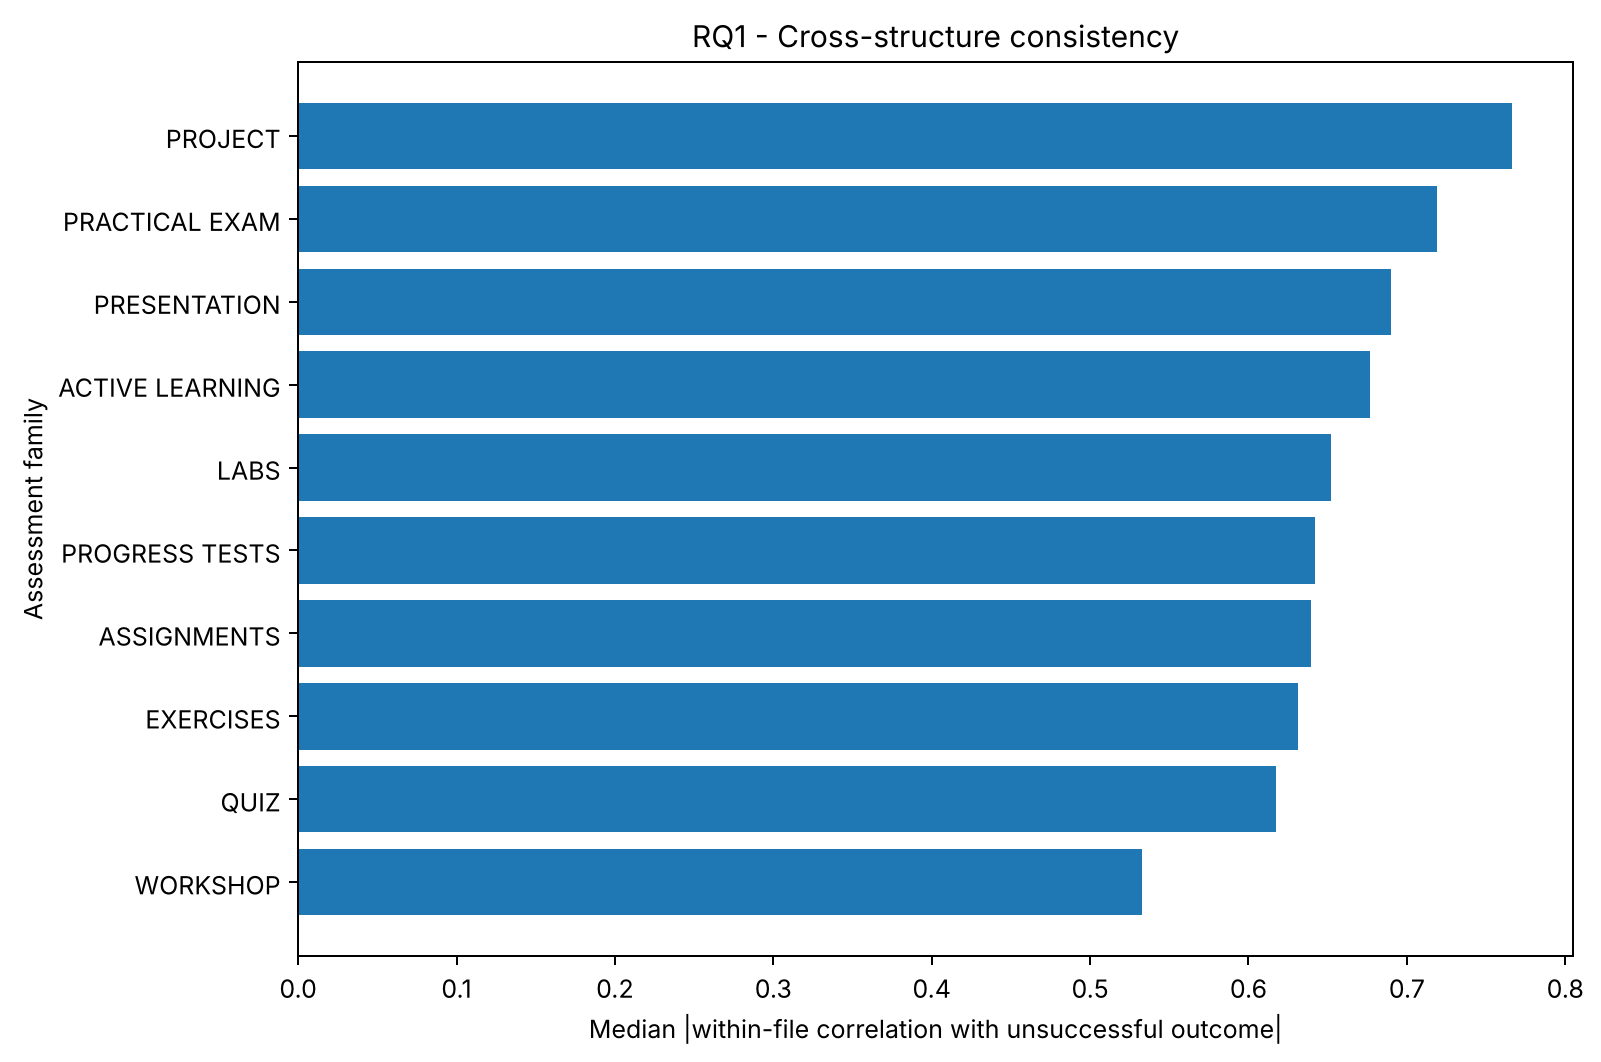

In [7]:
# ------------------------------------------------------------
# 3. RQ1 - CROSS-STRUCTURE CONSISTENCY  (split-independent)
# ------------------------------------------------------------
def family_name(feature: str) -> str:
    # remove final numeric weight, e.g. PRACTICAL EXAM-30 -> PRACTICAL EXAM
    if "-" in feature and feature.rsplit("-", 1)[1].isdigit():
        return feature.rsplit("-", 1)[0]
    return feature

within_rows = []

for source_file, g in model_df.groupby("SOURCE_FILE"):
    for feat in FEATURES:
        if feat not in g.columns:
            continue
        sub = g[[feat, "TARGET"]].dropna()
        if len(sub) < MIN_RQ1_N_WITHIN_FILE:
            continue
        if sub[feat].nunique() < 2 or sub["TARGET"].nunique() < 2:
            continue
        corr = float(np.corrcoef(sub[feat].astype(float), sub["TARGET"].astype(float))[0, 1])
        within_rows.append({
            "source_file": source_file,
            "assessment_component": feat,
            "assessment_family": family_name(feat),
            "n": len(sub),
            "correlation": corr,
            "absolute_correlation": abs(corr),
            "avg_successful": float(sub.loc[sub.TARGET == 0, feat].mean()),
            "avg_unsuccessful": float(sub.loc[sub.TARGET == 1, feat].mean()),
        })

rq1_within = pd.DataFrame(within_rows)
rq1_within.to_csv(OUT_DIR / "RQ1_within_file_correlations.csv", index=False, encoding="utf-8-sig")

rq1_family = (
    rq1_within.groupby("assessment_family")
    .agg(
        distinct_files=("source_file", "nunique"),
        component_file_pairs=("source_file", "size"),
        total_n=("n", "sum"),
        median_correlation=("correlation", "median"),
        median_abs_correlation=("absolute_correlation", "median"),
        min_correlation=("correlation", "min"),
        max_correlation=("correlation", "max"),
    )
    .reset_index()
    .sort_values(["median_abs_correlation", "distinct_files"], ascending=[False, False])
)
rq1_family.to_csv(OUT_DIR / "RQ1_cross_structure_consistency.csv", index=False, encoding="utf-8-sig")
# Main RQ1 conclusion: require support from at least 5 distinct sources.
rq1_reliable = rq1_family[rq1_family["distinct_files"] >= 5].copy()
rq1_reliable.to_csv(OUT_DIR / "RQ1_top_assessment_families.csv", index=False, encoding="utf-8-sig")


print("\n=== RQ1: CROSS-STRUCTURE CONSISTENCY ===")
print(rq1_family.to_string(index=False))

plot_rq1 = rq1_family.sort_values("median_abs_correlation")
plt.figure(figsize=(9, 6))
plt.barh(plot_rq1["assessment_family"], plot_rq1["median_abs_correlation"])
plt.xlabel("Median |within-file correlation with unsuccessful outcome|")
plt.ylabel("Assessment family")
plt.title("RQ1 - Cross-structure consistency")
plt.tight_layout()
plt.savefig(OUT_DIR / "RQ1_cross_structure_consistency.png", dpi=180, bbox_inches="tight")
plt.close()

from IPython.display import Image, display
print('Xếp hạng họ đánh giá có ít nhất 5 nguồn:')
display(rq1_reliable[['assessment_family','distinct_files','median_correlation','median_abs_correlation']].head(10))
display(Image(filename=str(OUT_DIR / 'RQ1_cross_structure_consistency.png')))


**Biện luận RQ1 theo kết quả FULL của v1.1:** `PRACTICAL EXAM` đứng đầu trong nhóm có dữ liệu từ ít nhất 5 nguồn, với **median |r| ≈ 0,7193**, hiện diện ở **10 nguồn**. Dấu âm cho thấy điểm thực hành thấp thường đi kèm rủi ro không đạt cao hơn. Tuy nhiên, điều này **không đủ để khẳng định** nâng điểm thực hành sẽ trực tiếp gây ra thay đổi ở kết quả cuối kỳ; còn phụ thuộc cấu trúc đánh giá và các biến chưa quan sát.

## 6. Chia train / validation / test có kiểm soát nhóm

**Giải thích:** Dùng `GroupShuffleSplit` với khóa ghép `SOURCE_FILE + CODE`. Lần chia 1 lấy 20% làm test; lần chia 2 tách 25% tập development làm validation, tạo tỷ lệ xấp xỉ 60% / 20% / 20%.

**Biện luận:** Các bản ghi cùng một `SOURCE_FILE + CODE` phải nằm cùng một tập để giảm nguy cơ trùng lặp thông tin. **Validation** dùng chọn mô hình/ngưỡng; **test** giữ độc lập để đánh giá sau cùng. Không được nhìn kết quả test rồi sửa mô hình để tối ưu trên test.

In [8]:
# ------------------------------------------------------------
# 4. TRAIN / VALIDATION / TEST SPLIT  (composite group key)
# ------------------------------------------------------------
X = model_df[FEATURES].copy()
y = model_df["TARGET"].copy()

# Canonical grouping: (SOURCE_FILE, CODE). CODE is meaningful only
# within SOURCE_FILE (methodological decision Q3), so the composite
# key is the correct grouping unit. Global CODE grouping is NOT used.
group_key = (
    model_df["SOURCE_FILE"].astype(str) + "___" + model_df["CODE"].astype(str)
)

if (
    USE_GROUP_SPLIT
    and model_df["CODE"].notna().all()
    and model_df["SOURCE_FILE"].notna().all()
):
    groups = group_key
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    dev_pos, test_pos = next(gss1.split(X, y, groups=groups))

    X_dev = X.iloc[dev_pos].copy()
    y_dev = y.iloc[dev_pos].copy()
    groups_dev = groups.iloc[dev_pos].copy()
    X_test = X.iloc[test_pos].copy()
    y_test = y.iloc[test_pos].copy()

    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
    train_pos, val_pos = next(gss2.split(X_dev, y_dev, groups=groups_dev))
    X_train = X_dev.iloc[train_pos].copy()
    y_train = y_dev.iloc[train_pos].copy()
    X_val = X_dev.iloc[val_pos].copy()
    y_val = y_dev.iloc[val_pos].copy()
    split_strategy = "GroupShuffleSplit by (SOURCE_FILE, CODE)"
else:
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE
    )
    split_strategy = "Stratified random split"

# Group-level audit on the composite key (works for both branches).
train_index = X_train.index
val_index = X_val.index
test_index = X_test.index
train_groups = set(group_key.loc[train_index])
val_groups = set(group_key.loc[val_index])
test_groups = set(group_key.loc[test_index])
group_overlap = {
    "train_validation": len(train_groups & val_groups),
    "train_test": len(train_groups & test_groups),
    "validation_test": len(val_groups & test_groups),
}

print("\n=== SPLIT ===")
for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:10s}: {len(yy):,} | TARGET1={100*yy.mean():.2f}%")
print("Strategy:", split_strategy)
print(
    "Groups (train/val/test): "
    f"{len(train_groups):,} / {len(val_groups):,} / {len(test_groups):,}"
)
print("Group overlap (train-val/train-test/val-test):", group_overlap)

split_summary = pd.DataFrame([
    {"split": "train", "n": len(y_train), "target1_pct": 100*y_train.mean()},
    {"split": "validation", "n": len(y_val), "target1_pct": 100*y_val.mean()},
    {"split": "test", "n": len(y_test), "target1_pct": 100*y_test.mean()},
])
split_summary.to_csv(OUT_DIR / "01_split_summary.csv", index=False, encoding="utf-8-sig")

# Deterministic split artifact: exact row indices + composite group key,
# so the split can be independently reconstructed.
split_indices = pd.concat([
    pd.DataFrame({
        "index": train_index,
        "split": "train",
        "group_key": group_key.loc[train_index].values,
    }),
    pd.DataFrame({
        "index": val_index,
        "split": "validation",
        "group_key": group_key.loc[val_index].values,
    }),
    pd.DataFrame({
        "index": test_index,
        "split": "test",
        "group_key": group_key.loc[test_index].values,
    }),
], ignore_index=True)
split_indices.to_csv(OUT_DIR / "split_indices.csv", index=False, encoding="utf-8-sig")

# NO IMPUTATION (v1.1). Missing assessment scores are kept as NaN because
# each course only records some assessment components. DT/RF (scikit-learn
# >= 1.4), XGBoost, LightGBM and CatBoost handle NaN natively.
# SMOTE cannot process NaN, so ONLY the SMOTE scenarios use a median
# imputer fitted on the training partition (see section 6). All
# non-SMOTE results (RQ2 and the baseline in RQ3) use the raw NaN data.
X_train_imp, X_val_imp, X_test_imp = X_train, X_val, X_test

print('Bảng chia dữ liệu:')
display(split_summary)
assert sum(group_overlap.values()) == 0, 'Có chồng nhóm giữa các tập dữ liệu'



=== SPLIT ===
Train     : 66,491 | TARGET1=26.08%
Validation: 22,236 | TARGET1=26.40%
Test      : 21,977 | TARGET1=25.90%
Strategy: GroupShuffleSplit by (SOURCE_FILE, CODE)
Groups (train/val/test): 54,079 / 18,027 / 18,027
Group overlap (train-val/train-test/val-test): {'train_validation': 0, 'train_test': 0, 'validation_test': 0}
Bảng chia dữ liệu:


,split,n,target1_pct
0,train,66491,26.075709
1,validation,22236,26.398633
2,test,21977,25.895254


**Kiểm tra điều kiện:** `group_overlap` phải bằng **0** cho cả ba cặp train–validation, train–test và validation–test. Nhánh RQ2 **không điền thiếu** (`NaN`) vì pipeline v1.1 sử dụng khả năng xử lý thiếu trực tiếp của các mô hình. Điền thiếu bằng toàn bộ dữ liệu trước khi chia sẽ tạo rủi ro leakage.

## 7. RQ2 — Huấn luyện và so sánh năm thuật toán

**Câu hỏi:** *Which of five algorithms performs best for the early-warning task?*

Năm mô hình: **Decision Tree, Random Forest, XGBoost, LightGBM và CatBoost**. Giữ cấu hình v1.1 và so sánh tại threshold **0,50** trên tập **validation**. Mục tiêu là **F2-score** (ưu tiên Recall hơn Precision):

\[F_2 = \frac{5 \cdot Precision\cdot Recall}{4\cdot Precision+Recall}\]

**Biện luận:** Hệ thống cảnh báo sớm cần hạn chế **false negative** (sinh viên có nguy cơ nhưng không được cảnh báo), nên dùng F2 để trọng số Recall lớn hơn. Tuy nhiên, F2 cao không đồng nghĩa khả năng tổng quát hóa tuyệt đối; cần xem thêm PR-AUC, Precision và Recall.

In [9]:
# ------------------------------------------------------------
# 5. RQ2 - FIVE MODEL COMPARISON
# ------------------------------------------------------------
# Convention: all five models are compared on VALIDATION only.
# The best model is selected by validation F2, and the untouched
# TEST set is used ONCE, for the SELECTED model only. Test metrics
# are never used to select, tune, or optimize anything.
def registry():
    return {
        "Decision Tree": DecisionTreeClassifier(
            random_state=RANDOM_STATE, class_weight="balanced"
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=30 if QUICK_CHECK else 300, random_state=RANDOM_STATE,
            class_weight="balanced", n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=30 if QUICK_CHECK else 300, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=30 if QUICK_CHECK else 300, learning_rate=0.05,
            random_state=RANDOM_STATE, verbosity=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=30 if QUICK_CHECK else 300, depth=6, learning_rate=0.05,
            random_seed=RANDOM_STATE, verbose=False
        ),
    }


def prob(model, XX):
    return model.predict_proba(XX)[:, 1]


def metrics(y_true, p, threshold=0.50):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "roc_auc": roc_auc_score(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

fitted = {}
rq2_rows = []
for name, model in registry().items():
    print(f"Training {name}...")
    model.fit(X_train_imp, y_train)
    fitted[name] = model
    val_m = metrics(y_val, prob(model, X_val_imp), 0.50)
    rq2_rows.append({
        "model": name,
        **{f"val_{k}": v for k, v in val_m.items()},
    })

rq2 = pd.DataFrame(rq2_rows).sort_values(
    ["val_f2", "val_recall", "val_pr_auc"], ascending=False
).reset_index(drop=True)
best_name = rq2.iloc[0]["model"]

# Evaluate the SELECTED model ONCE on the untouched test set.
# Test metrics are reported for the selected model only; the other
# models' test metrics are intentionally not computed (no test-based
# selection, tuning, or optimization).
best_test_m = metrics(y_test, prob(fitted[best_name], X_test_imp), 0.50)
for k, v in best_test_m.items():
    rq2.loc[rq2["model"] == best_name, f"test_{k}"] = v

rq2.to_csv(OUT_DIR / "RQ2_model_comparison.csv", index=False, encoding="utf-8-sig")

print("\n=== RQ2: MODEL COMPARISON (selected by validation F2) ===")
print(rq2[["model", "val_f2", "val_recall", "val_pr_auc"]].to_string(index=False))
print(
    f"Selected model: {best_name} | "
    f"test F2={best_test_m['f2']:.4f}, recall={best_test_m['recall']:.4f}, "
    f"precision={best_test_m['precision']:.4f} (test evaluated once, selected model only)"
)

print('Bảng so sánh năm mô hình:')
display(rq2[['model','val_precision','val_recall','val_f1','val_f2','val_pr_auc']].style.format(precision=4))


Training Decision Tree...


Training Random Forest...


Training XGBoost...


Training LightGBM...


Training CatBoost...



=== RQ2: MODEL COMPARISON (selected by validation F2) ===
        model   val_f2  val_recall  val_pr_auc
Random Forest 0.856648    0.858603    0.930897
     LightGBM 0.847517    0.826235    0.946399
      XGBoost 0.845090    0.822487    0.946211
     CatBoost 0.839266    0.815332    0.944607
Decision Tree 0.837419    0.843782    0.783516
Selected model: Random Forest | test F2=0.8409, recall=0.8399, precision=0.8447 (test evaluated once, selected model only)
Bảng so sánh năm mô hình:


,model,val_precision,val_recall,val_f1,val_f2,val_pr_auc
0,Random Forest,0.8489,0.8586,0.8537,0.8566,0.9309
1,LightGBM,0.9449,0.8262,0.8816,0.8475,0.9464
2,XGBoost,0.9495,0.8225,0.8814,0.8451,0.9462
3,CatBoost,0.9509,0.8153,0.8779,0.8393,0.9446
4,Decision Tree,0.8129,0.8438,0.8281,0.8374,0.7835


**Giải thích và biện luận RQ2:**

- Mô hình được chọn là mô hình có **validation F2 cao nhất tại ngưỡng 0,50**; tập test **chỉ** được dùng một lần để đánh giá mô hình đã chọn, không dùng để chọn hay chỉnh.
- Khoảng cách giữa các mô hình hàng đầu rất nhỏ và chỉ dựa trên **một lần chia dữ liệu với một `random_state`**; vì vậy kết quả là bằng chứng mô tả, không phải khẳng định thuật toán nào vượt trội tổng quát.
- Thứ hạng các mô hình cây (nhất là Random Forest so với LightGBM) có thể thay đổi theo phiên bản thư viện, nên cần chạy đúng môi trường đã ghim ở mục 0 và đối chiếu mục 14.
- Mô hình được chọn theo F2 ở ngưỡng 0,50 chưa chắc vẫn tốt nhất sau khi tinh chỉnh ngưỡng ở RQ3.

## 8. RQ3 — Tối ưu threshold cho Baseline

**Câu hỏi:** *Does SMOTE, together with F2-based threshold tuning, improve the recall-oriented performance of the selected model?*

**Giải thích:** Trước tiên huấn luyện lại mô hình được chọn **không SMOTE**, quét ngưỡng từ `0.05` đến `0.95`, bước `0.01`, chỉ dùng **validation F2** để chọn ngưỡng. Sau đó đánh giá trên test.

**Biện luận:** Threshold mặc định `0.50` chưa chắc phù hợp với bài toán ưu tiên phát hiện các trường hợp không đạt. **Không được dùng test để tối ưu threshold**, nếu không hiệu năng test sẽ bị thổi phồng.

In [10]:
# 6. RQ3 - BASELINE VS SMOTE + VALIDATION F2 THRESHOLD
# ------------------------------------------------------------
def best_f2_threshold(y_true, p):
    rows = []
    for t in np.arange(0.05, 0.951, 0.01):
        pred = (p >= t).astype(int)
        rows.append({
            "threshold": float(t),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        })
    tbl = pd.DataFrame(rows)
    best = tbl.sort_values(["f2", "recall", "precision"], ascending=False).iloc[0]
    return float(best["threshold"]), tbl

baseline = registry()[best_name]
baseline.fit(X_train_imp, y_train)
baseline_val_p = prob(baseline, X_val_imp)
baseline_t, baseline_thresholds = best_f2_threshold(y_val, baseline_val_p)
baseline_test_p = prob(baseline, X_test_imp)
baseline_m = metrics(y_test, baseline_test_p, baseline_t)

print('Threshold Baseline chọn từ validation:', round(baseline_t, 3))
print('F2 Baseline trên test:', round(baseline_m['f2'], 4))


Threshold Baseline chọn từ validation: 0.39
F2 Baseline trên test: 0.8403


## 9. RQ3 — Thử nghiệm SMOTE và threshold tuning

**Giải thích:** SMOTE tạo thêm ví dụ cho lớp thiểu số **chỉ trên train**. Vì SMOTE không chấp nhận `NaN`, pipeline sử dụng `SimpleImputer(strategy="median")` **fit trên train** rồi transform validation/test; sau đó tìm threshold tối ưu F2 trên validation và đánh giá test.

**Biện luận:** Không đưa SMOTE vào validation/test để tránh làm méo phân bố đánh giá. Vì baseline không điền thiếu nhưng nhánh SMOTE có điền thiếu, phần kiểm soát bên dưới cần tách tác động của **imputation** khỏi tác động thực sự của **SMOTE**.

In [11]:
# SMOTE branch only: SMOTE requires complete data, so a median imputer
# fitted on TRAIN is applied to train/val/test for these scenarios.
smote_imputer = SimpleImputer(strategy="median")
X_train_si = pd.DataFrame(smote_imputer.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_val_si = pd.DataFrame(smote_imputer.transform(X_val), columns=FEATURES, index=X_val.index)
X_test_si = pd.DataFrame(smote_imputer.transform(X_test), columns=FEATURES, index=X_test.index)
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_si, y_train)
smote_model = registry()[best_name]
smote_model.fit(X_train_sm, y_train_sm)
smote_val_p = prob(smote_model, X_val_si)
smote_t, smote_thresholds = best_f2_threshold(y_val, smote_val_p)
smote_test_p = prob(smote_model, X_test_si)
smote_m = metrics(y_test, smote_test_p, smote_t)

print('Threshold SMOTE chọn từ validation:', round(smote_t, 3))
print('F2 SMOTE trên test:', round(smote_m['f2'], 4))


Threshold SMOTE chọn từ validation: 0.34
F2 SMOTE trên test: 0.8435


## 10. RQ3 — Kiểm soát imputation và so sánh bốn kịch bản

Bốn kịch bản giúp xem hiệu quả của **threshold tuning** và **SMOTE** riêng rẽ:

- Baseline @ 0.50
- Baseline + F2 tuning
- SMOTE @ 0.50
- SMOTE + F2 tuning

Ngoài ra, pipeline có **imputed baseline không SMOTE** để đánh giá riêng ảnh hưởng của việc điền giá trị thiếu.

**Biện luận:** Một cải thiện nhỏ ở F2 chưa chắc đồng nghĩa Recall được cải thiện; phải báo cáo cả Recall, Precision, số false negative (`FN`) và chênh lệch giữa các kịch bản.

In [12]:
# Supplementary control (NOT one of the four scenarios): same median-imputed
# data as the SMOTE branch but WITHOUT SMOTE, to separate the effect of
# imputation from the effect of SMOTE.
ctrl_model = registry()[best_name]
ctrl_model.fit(X_train_si, y_train)
ctrl_t, _ = best_f2_threshold(y_val, prob(ctrl_model, X_val_si))
ctrl_test_p = prob(ctrl_model, X_test_si)
pd.DataFrame([
    {"scenario": "Imputed baseline @ 0.50", **metrics(y_test, ctrl_test_p, 0.50)},
    {"scenario": "Imputed baseline + F2 tuning", **metrics(y_test, ctrl_test_p, ctrl_t)},
]).to_csv(OUT_DIR / "RQ3_control_imputed_no_smote.csv", index=False, encoding="utf-8-sig")

rq3 = pd.DataFrame([
    {"setting": f"{best_name} - baseline", **baseline_m},
    {"setting": f"{best_name} - SMOTE", **smote_m},
])
for k in ["precision", "recall", "f1", "f2", "roc_auc", "pr_auc"]:
    rq3[f"delta_{k}_vs_baseline"] = rq3[k] - rq3.loc[0, k]

rq3.to_csv(OUT_DIR / "RQ3_baseline_vs_smote.csv", index=False, encoding="utf-8-sig")
baseline_thresholds.to_csv(OUT_DIR / "RQ3_baseline_validation_thresholds.csv", index=False)
smote_thresholds.to_csv(OUT_DIR / "RQ3_smote_validation_thresholds.csv", index=False)

# Additional RQ3 ablation: isolate threshold tuning vs SMOTE.
# This evaluation never uses test for model/threshold selection.
ablations = pd.DataFrame([
    {"scenario": "Baseline @ 0.50", **metrics(y_test, baseline_test_p, 0.50)},
    {"scenario": "Baseline + F2 tuning", **baseline_m},
    {"scenario": "SMOTE @ 0.50", **metrics(y_test, smote_test_p, 0.50)},
    {"scenario": "SMOTE + F2 tuning", **smote_m},
])
ablations.to_csv(OUT_DIR / "RQ3_four_scenarios.csv", index=False, encoding="utf-8-sig")

print("\n=== RQ3: BASELINE VS SMOTE ===")
print(rq3[["setting", "threshold", "precision", "recall", "f1", "f2", "roc_auc", "pr_auc", "fp", "fn", "tp"]].round(4).to_string(index=False))


# ------------------------------------------------------------

print('Bốn kịch bản trên tập test:')
display(ablations[['scenario','threshold','precision','recall','f1','f2','fp','fn']].style.format(precision=4))
print('Baseline đã điền thiếu nhưng không SMOTE:')
display(pd.read_csv(OUT_DIR / 'RQ3_control_imputed_no_smote.csv')[['scenario','f2','recall','precision']].style.format(precision=4))



=== RQ3: BASELINE VS SMOTE ===
                 setting  threshold  precision  recall     f1     f2  roc_auc  pr_auc   fp  fn   tp
Random Forest - baseline       0.39     0.7721  0.8593 0.8134 0.8403   0.9456  0.9192 1443 801 4890
   Random Forest - SMOTE       0.34     0.7941  0.8568 0.8243 0.8435   0.9418  0.9175 1264 815 4876
Bốn kịch bản trên tập test:


,scenario,threshold,precision,recall,f1,f2,fp,fn
0,Baseline @ 0.50,0.5000,0.8447,0.8399,0.8423,0.8409,879,911
1,Baseline + F2 tuning,0.3900,0.7721,0.8593,0.8134,0.8403,1443,801
2,SMOTE @ 0.50,0.5000,0.8751,0.8274,0.8506,0.8366,672,982
3,SMOTE + F2 tuning,0.3400,0.7941,0.8568,0.8243,0.8435,1264,815


Baseline đã điền thiếu nhưng không SMOTE:


,scenario,f2,recall,precision
0,Imputed baseline @ 0.50,0.8406,0.8392,0.8461
1,Imputed baseline + F2 tuning,0.8408,0.8677,0.7481


**Giải thích và biện luận RQ3:**

- Số liệu của lần chạy này nằm ở bảng bốn kịch bản (mục 10) và ở kết luận tự động (mục 13). Notebook không ghi cứng con số để tránh mâu thuẫn với kết quả thực tế.
- **Tinh chỉnh ngưỡng** làm recall tăng và precision giảm; mức thay đổi F2 phụ thuộc kịch bản và cần đọc trên bảng.
- **SMOTE + tinh chỉnh** so với **baseline + tinh chỉnh** chỉ chênh nhau rất ít về F2, và dấu của chênh lệch đổi chiều khi đổi môi trường thư viện hoặc cách xử lý dữ liệu (các phân tích độ nhạy của nhóm). Vì vậy **không kết luận được rằng SMOTE cải thiện hay làm giảm hiệu quả cảnh báo sớm**.
- Nhánh SMOTE cần điền thiếu (median, fit trên train) còn baseline thì không; đối chứng *imputed baseline* ở mục 10 giúp tách tác động của điền thiếu khỏi tác động của SMOTE.
- Không có kiểm định thống kê cho chênh lệch nhỏ từ một lần chia dữ liệu.

## 11. Trực quan hóa và xuất kết quả

**Giải thích:** Biểu đồ giúp nhìn rõ mức tương quan (RQ1), thứ tự F2 của 5 mô hình (RQ2) và hiệu quả giữa bốn kịch bản (RQ3). Các file CSV/PNG được lưu trong `KET_QUA_CHAY_NOTEBOOK_V1_1` để thuận tiện đưa vào báo cáo.

**Biện luận:** Trục biểu đồ RQ2/RQ3 cần thể hiện rõ **validation** hay **test**, tránh so sánh nhầm thước đo trên hai tập khác nhau. Các biểu đồ hỗ trợ, không thay thế bảng số liệu và nhận xét về độ lớn chênh lệch.

RQ2 — Validation F2 của 5 mô hình


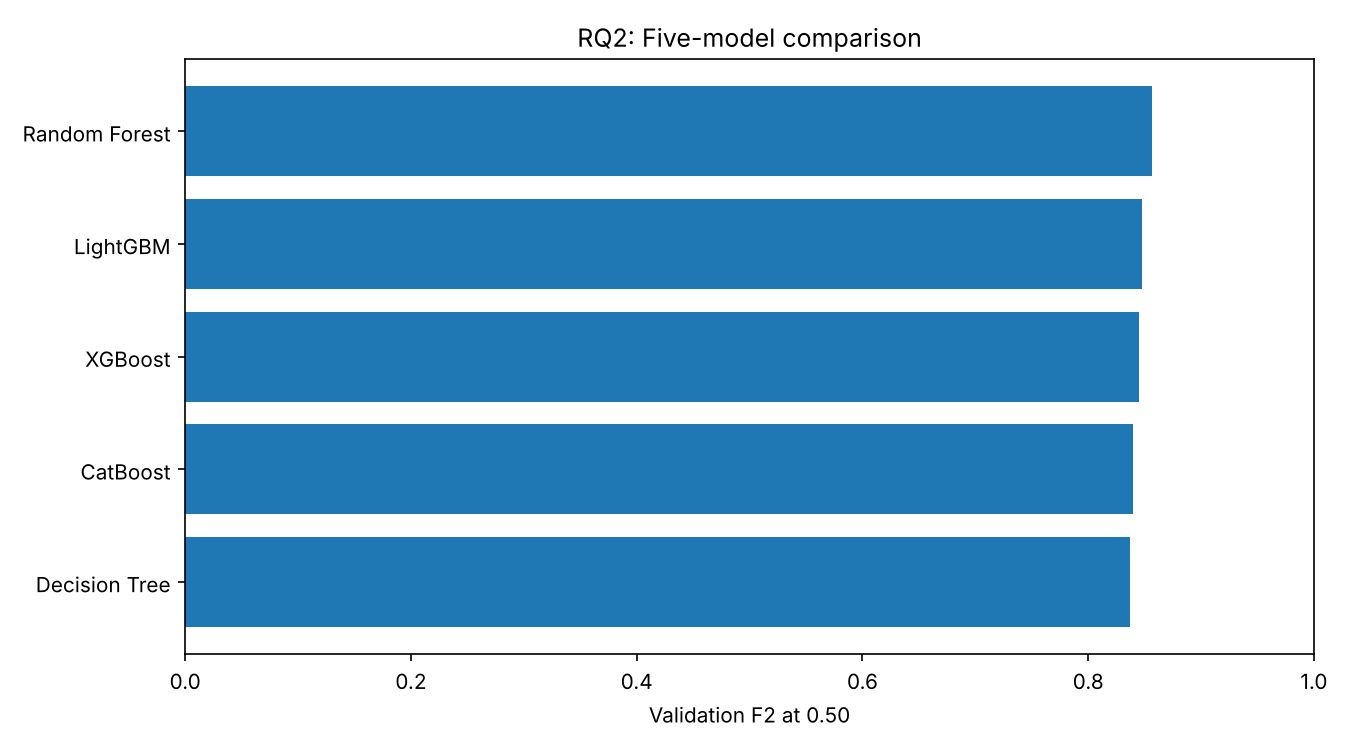

RQ3 — Test F2 của 4 kịch bản


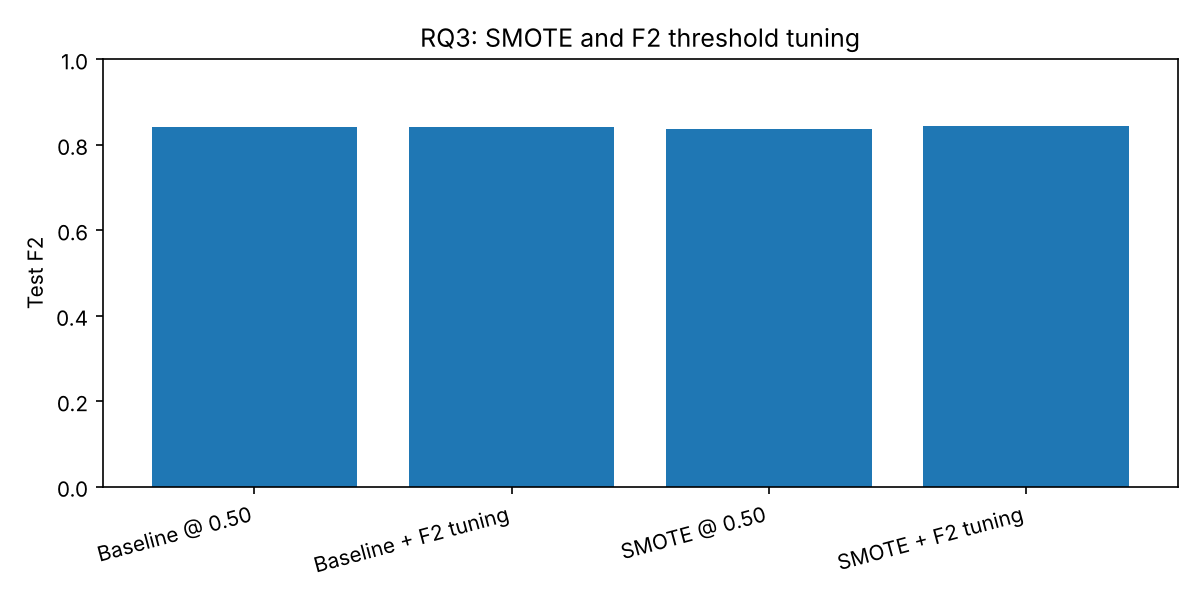

In [13]:
# 7. CHARTS AND SUMMARY - ONLY 3 RQs
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.barh(rq2["model"][::-1], rq2["val_f2"][::-1])
plt.xlim(0, 1)
plt.xlabel("Validation F2 at 0.50")
plt.title("RQ2: Five-model comparison")
plt.tight_layout()
plt.savefig(OUT_DIR / "RQ2_model_comparison.png", dpi=150)
plt.close()

plt.figure(figsize=(8, 4))
plt.bar(ablations["scenario"], ablations["f2"])
plt.ylim(0, 1)
plt.ylabel("Test F2")
plt.title("RQ3: SMOTE and F2 threshold tuning")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUT_DIR / "RQ3_four_scenarios.png", dpi=150)
plt.close()

print('RQ2 — Validation F2 của 5 mô hình')
display(Image(filename=str(OUT_DIR / 'RQ2_model_comparison.png')))
print('RQ3 — Test F2 của 4 kịch bản')
display(Image(filename=str(OUT_DIR / 'RQ3_four_scenarios.png')))


## 12. Metadata và kết quả tái lập

**Giải thích:** Ô dưới giữ nguyên cơ chế xuất `TONG_KET_RQ1_RQ2_RQ3.txt`, `run_metadata.json` cùng cấu hình, phiên bản thư viện, số dòng, mô hình chọn và ngưỡng tối ưu của script gốc.

**Biện luận:** Khi nộp bài, kết quả cần đi kèm **nguồn dữ liệu, cách chia tập, tham số và phiên bản thư viện**. Điều này giúp phân biệt kết quả có thể kiểm chứng với phát biểu không có bằng chứng.

In [14]:
summary = [
    "ADY201m - KET QUA PIPELINE CHI RQ1, RQ2, RQ3",
    "=" * 58,
    f"Version: {SCRIPT_VERSION}",
    f"Mode: {'QUICK-CHECK - DO NOT REPORT' if QUICK_CHECK else 'FULL ORIGINAL PARAMETERS'}",
    f"Data: {combined_path.name} | total_rows={len(df)} | modeling_rows={len(model_df)}",
    f"Split: {split_strategy} | overlap={group_overlap}",
]
if not rq1_reliable.empty:
    winner = rq1_reliable.iloc[0]
    summary.append(
        f"RQ1: {winner['assessment_family']} highest median |Pearson r|="
        f"{winner['median_abs_correlation']:.4f} in {int(winner['distinct_files'])} sources (>=5 sources)."
    )
else:
    summary.append("RQ1: No feature family replicated in at least 5 sources; no stable winner.")
summary += [
    f"RQ2: Best model={best_name}; validation F2={float(rq2.iloc[0]['val_f2']):.4f}; selected model test F2@0.50={best_test_m['f2']:.4f}.",
    f"RQ3: Baseline+tuning F2={baseline_m['f2']:.4f}, SMOTE+tuning F2={smote_m['f2']:.4f}, delta={smote_m['f2'] - baseline_m['f2']:+.4f}.",
    f"RQ3: Recall baseline={baseline_m['recall']:.4f}, SMOTE={smote_m['recall']:.4f}, delta={smote_m['recall']-baseline_m['recall']:+.4f}.",
    "Notes: Associations do not imply causation. Thresholds optimized using validation only.",
    "Notes: No imputation except inside the SMOTE scenarios (SMOTE cannot handle NaN).",
    "Notes: Class 1=unsuccessful. Scores from quick-check mode are NOT for the final report.",
]
(OUT_DIR / "TONG_KET_RQ1_RQ2_RQ3.txt").write_text("\n".join(summary), encoding="utf-8")
print("\n" + "\n".join(summary))

# Sufficient metadata to trace real training and reproducibility.
def version_of(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return "not found"

def serializable(x):
    if isinstance(x, dict):
        return {str(k): serializable(v) for k,v in x.items()}
    if isinstance(x, (list,tuple)):
        return [serializable(v) for v in x]
    if isinstance(x, np.generic):
        return x.item()
    return x

metadata={
    "script": SCRIPT_VERSION,
    "mode": "quick-check" if QUICK_CHECK else "full",
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python_version": platform.python_version(),
    "package_versions": {p: version_of(p) for p in ["numpy","pandas","scikit-learn","imbalanced-learn","xgboost","lightgbm","catboost","matplotlib"]},
    "input_path": str(combined_path),
    "rows_total": len(df), "rows_model": len(model_df),
    "target_definition": {"0": "successful", "1": "unsuccessful"},
    "predictors": FEATURES,
    "excluded_leakage_features": ["FINAL EXAM", "FINAL EXAM-30", "FINAL EXAM-40", "TOTAL", "STATUS", "STATUS_CLEAN", "TARGET"],
    "split": split_strategy,
    "split_group_overlap": group_overlap,
    "split_sizes": {"train":len(y_train), "validation":len(y_val), "test":len(y_test)},
    "model_parameters": {k:repr(v) for k,v in registry().items()},
    "selected_model": best_name,
    "validation_f2_at_0_5": float(rq2.iloc[0]["val_f2"]),
    "threshold_search": "0.05 to 0.95 inclusive, step 0.01 on validation",
    "baseline_threshold": baseline_t,
    "smote_threshold": smote_t,
    "baseline_test_metrics": baseline_m,
    "smote_test_metrics": smote_m,
    "random_state": RANDOM_STATE,
    "imputation": "none for RQ2 and baseline (native NaN handling); median imputer fitted on train used ONLY in the SMOTE scenarios",
}
(OUT_DIR / "run_metadata.json").write_text(json.dumps(serializable(metadata),ensure_ascii=False,indent=2), encoding="utf-8")
print(f"\n[OK] Da xuat ket qua: {OUT_DIR}")

print('\nCác tệp đã xuất:')
for p in sorted(OUT_DIR.glob('*')):
    print('•', p.name)



ADY201m - KET QUA PIPELINE CHI RQ1, RQ2, RQ3
Version: ADY201m_PIPELINE_CHI_RQ1_RQ2_RQ3 v1.1 (no imputation; goc: GROUPED v1.0.0)
Mode: FULL ORIGINAL PARAMETERS
Data: ADY201m_combined_cleaned.csv | total_rows=124791 | modeling_rows=110704
Split: GroupShuffleSplit by (SOURCE_FILE, CODE) | overlap={'train_validation': 0, 'train_test': 0, 'validation_test': 0}
RQ1: PRACTICAL EXAM highest median |Pearson r|=0.7193 in 10 sources (>=5 sources).
RQ2: Best model=Random Forest; validation F2=0.8566; selected model test F2@0.50=0.8409.
RQ3: Baseline+tuning F2=0.8403, SMOTE+tuning F2=0.8435, delta=+0.0032.
RQ3: Recall baseline=0.8593, SMOTE=0.8568, delta=-0.0025.
Notes: Associations do not imply causation. Thresholds optimized using validation only.
Notes: No imputation except inside the SMOTE scenarios (SMOTE cannot handle NaN).
Notes: Class 1=unsuccessful. Scores from quick-check mode are NOT for the final report.

[OK] Da xuat ket qua: /tmp/claude-0/-home-claude/86b98766-2cfc-5df3-accc-f3ea712

## 13. Kết luận tự động từ **lần chạy notebook hiện tại**

**Giải thích:** Bảng tổng hợp và đoạn kết luận phía dưới được tạo **từ biến kết quả của chính lần chạy này**, không lấy cứng các con số từ lần chạy cũ. Bạn nên đọc đoạn này sau khi nhấn **Chạy tất cả (Run all)**. Ô này trình bày kết luận bằng định dạng Markdown để có thể sao chép vào báo cáo.

In [15]:
from IPython.display import Markdown, display
w = rq1_reliable.iloc[0] if not rq1_reliable.empty else None
r2_best = rq2.iloc[0]
r2_second = rq2.iloc[1]
base = ablations.set_index('scenario').loc['Baseline + F2 tuning']
sm = ablations.set_index('scenario').loc['SMOTE + F2 tuning']
f2_delta = sm['f2'] - base['f2']
recall_delta = sm['recall'] - base['recall']
f2_word = 'tăng' if f2_delta > 0 else ('giảm' if f2_delta < 0 else 'không đổi')
recall_word = 'tăng' if recall_delta > 0 else ('giảm' if recall_delta < 0 else 'không đổi')
rq1_summary = (f"**{w['assessment_family']}** (median |r| = {w['median_abs_correlation']:.4f}, "
               f"{int(w['distinct_files'])} nguồn)" if w is not None else 'Không có nhóm đánh giá đạt ngưỡng 5 nguồn')
conclusion = f"""## KẾT LUẬN TỪ KẾT QUẢ ĐÃ CHẠY

**RQ1.** Nhóm điểm tiền final liên quan mạnh nhất với kết quả không đạt (trong các nhóm có từ 5 nguồn trở lên) là {rq1_summary}. Đây là quan hệ thống kê, không phải quan hệ nhân quả.

**RQ2.** Trong năm thuật toán, **{r2_best['model']}** đạt validation **F2 = {r2_best['val_f2']:.4f}** tại threshold 0,50, nên được chọn theo tiêu chí đã xác định trước (hạng 2: {r2_second['model']}, F2 = {r2_second['val_f2']:.4f}; chênh {r2_best['val_f2']-r2_second['val_f2']:.4f}, một lần chia với một `random_state`). Tập test không dùng để chọn mô hình.

**RQ3.** Baseline + tuning có test F2 = **{base['f2']:.4f}**; SMOTE + tuning có test F2 = **{sm['f2']:.4f}**. F2 **{f2_word} {abs(f2_delta):.4f}**. Recall **{recall_word} {abs(recall_delta):.4f}** (từ {base['recall']:.4f} đến {sm['recall']:.4f}). Vì vậy cần kết luận riêng cho F2 và Recall, không khẳng định cả hai cùng cải thiện nếu số liệu không ủng hộ.

**Giới hạn:** `CODE` chỉ được coi là mã sinh viên trong từng file môn; các bản ghi `(SOURCE_FILE, CODE, Mã học kỳ)` lặp lại (có sẵn trong Excel gốc, nhãn có thể mâu thuẫn) được giữ nguyên; khoảng 86% giá trị đầu vào bị thiếu vì mỗi môn chỉ có một số thành phần điểm (không điền thiếu, trừ nhánh SMOTE). Khác biệt giữa nguồn và chương trình học có thể ảnh hưởng mức tổng quát; tương quan không suy ra nhân quả; thay đổi thư viện/môi trường có thể làm biến động kết quả; phép so sánh SMOTE còn đi kèm bước điền thiếu nên cần xét đối chứng imputed baseline. Chưa có đánh giá bất định thống kê để khẳng định chênh lệch nhỏ có ý nghĩa trên quần thể."""
display(Markdown(conclusion))


## KẾT LUẬN TỪ KẾT QUẢ ĐÃ CHẠY

**RQ1.** Nhóm điểm tiền final liên quan mạnh nhất với kết quả không đạt (trong các nhóm có từ 5 nguồn trở lên) là **PRACTICAL EXAM** (median |r| = 0.7193, 10 nguồn). Đây là quan hệ thống kê, không phải quan hệ nhân quả.

**RQ2.** Trong năm thuật toán, **Random Forest** đạt validation **F2 = 0.8566** tại threshold 0,50, nên được chọn theo tiêu chí đã xác định trước (hạng 2: LightGBM, F2 = 0.8475; chênh 0.0091, một lần chia với một `random_state`). Tập test không dùng để chọn mô hình.

**RQ3.** Baseline + tuning có test F2 = **0.8403**; SMOTE + tuning có test F2 = **0.8435**. F2 **tăng 0.0032**. Recall **giảm 0.0025** (từ 0.8593 đến 0.8568). Vì vậy cần kết luận riêng cho F2 và Recall, không khẳng định cả hai cùng cải thiện nếu số liệu không ủng hộ.

**Giới hạn:** `CODE` chỉ được coi là mã sinh viên trong từng file môn; các bản ghi `(SOURCE_FILE, CODE, Mã học kỳ)` lặp lại (có sẵn trong Excel gốc, nhãn có thể mâu thuẫn) được giữ nguyên; khoảng 86% giá trị đầu vào bị thiếu vì mỗi môn chỉ có một số thành phần điểm (không điền thiếu, trừ nhánh SMOTE). Khác biệt giữa nguồn và chương trình học có thể ảnh hưởng mức tổng quát; tương quan không suy ra nhân quả; thay đổi thư viện/môi trường có thể làm biến động kết quả; phép so sánh SMOTE còn đi kèm bước điền thiếu nên cần xét đối chứng imputed baseline. Chưa có đánh giá bất định thống kê để khẳng định chênh lệch nhỏ có ý nghĩa trên quần thể.

---
## KẾT LUẬN CHUNG — RQ1, RQ2, RQ3

Số liệu cụ thể của lần chạy này nằm ở mục 13 (tự động tạo từ kết quả) và các bảng phía trên; không ghi cứng ở đây để tránh lệch số.

- **RQ1:** PRACTICAL EXAM là họ đánh giá có liên hệ mạnh nhất với kết quả không đạt trong các họ có dữ liệu từ ít nhất 5 nguồn (PROJECT có |r| lớn hơn nhưng chỉ có ở 2 nguồn). Tương quan âm, không chứng minh quan hệ nhân quả.
- **RQ2:** mô hình được chọn theo validation F2; khoảng cách giữa các mô hình hàng đầu nhỏ và phụ thuộc phiên bản thư viện.
- **RQ3:** tinh chỉnh ngưỡng tăng recall; không có bằng chứng SMOTE cải thiện F2 so với baseline đã tinh chỉnh.

**Các quyết định giảm rủi ro rò rỉ:** chỉ dùng điểm trước kỳ thi cuối kỳ; chia tập theo `SOURCE_FILE + CODE`; chọn mô hình và ngưỡng trên validation; giữ test để đánh giá cuối; bước điền thiếu (chỉ ở nhánh SMOTE) được fit trên train.

**Giới hạn chính:** một lần chia dữ liệu và một `random_state`; kết quả phụ thuộc phiên bản thư viện; `CODE` chỉ được xem là mã sinh viên trong từng file; các bản ghi lặp (4.812 tổ hợp, có sẵn trong Excel gốc) được giữ nguyên; phần lớn đầu vào bị thiếu theo cấu trúc môn học; chưa có kiểm định độ bất định cho chênh lệch nhỏ; đây là kết quả trên dữ liệu lịch sử của 18 môn, không suy rộng sang sinh viên hay môn học khác.

Notebook chỉ gồm RQ1–RQ3.

## 14. Đối chiếu tái lập với kết quả tham chiếu

**Giải thích:** Ô dưới so sánh kết quả của lần chạy này với kết quả của lần chạy tham chiếu (dùng trong báo cáo): mô hình được chọn, validation F2 của năm mô hình, test F2/recall của bốn kịch bản, kích thước các tập và họ đánh giá đứng đầu ở RQ1. Mô hình được chọn và kích thước tập phải **trùng khớp**; các chỉ số F2 và recall được chấp nhận trong dung sai 0,003 vì thứ tự tính toán đa luồng và phần cứng có thể gây chênh lệch cỡ 1e-4.

**Biện luận:** Nếu mọi mục khớp, kết quả được xem là tái lập. Nếu có mục lệch, nguyên nhân thường là phiên bản thư viện (xem mục 0), không phải lỗi dữ liệu; khi đó báo cáo chỉ nên trích dẫn **một** bộ số liệu (của lần chạy tham chiếu hoặc của lần chạy này), không trộn lẫn.

In [16]:
REFERENCE = {"run": "Lần chạy tham chiếu v1.1 (kết quả báo cáo)", "python": "3.14.5", "packages": {"numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1", "imbalanced-learn": "0.14.2", "xgboost": "3.4.1", "lightgbm": "4.7.0", "catboost": "1.2.10", "matplotlib": "3.11.2"}, "selected_model": "Random Forest", "val_f2": {"Random Forest": 0.856648, "LightGBM": 0.847517, "XGBoost": 0.845936, "CatBoost": 0.838626, "Decision Tree": 0.837419}, "test": {"Baseline @ 0.50": {"f2": 0.840868, "recall": 0.839923, "threshold": 0.5}, "Baseline + F2 tuning": {"f2": 0.840293, "recall": 0.859251, "threshold": 0.39}, "SMOTE @ 0.50": {"f2": 0.835613, "recall": 0.826568, "threshold": 0.5}, "SMOTE + F2 tuning": {"f2": 0.843255, "recall": 0.856264, "threshold": 0.34}}, "split_sizes": {"train": 66491, "validation": 22236, "test": 21977}, "rq1_top": {"family": "PRACTICAL EXAM", "median_abs_r": 0.719285, "files": 10}}
TOL = 0.003
rows = []
def add(item, got, ref, exact=False, tol=TOL):
    if exact: ok = (got == ref); diff = '' if ok else 'khác'
    else: diff = round(float(got) - float(ref), 6); ok = abs(diff) <= tol
    rows.append({'mục': item, 'lần chạy này': got if exact else round(float(got), 6), 'tham chiếu': ref, 'chênh': diff, 'khớp': 'OK' if ok else 'LỆCH'})

add('RQ2: mô hình được chọn', str(best_name), REFERENCE['selected_model'], exact=True)
for m_, v_ in REFERENCE['val_f2'].items():
    add(f'RQ2: validation F2 · {m_}', rq2.set_index('model').loc[m_, 'val_f2'], v_)
ab = ablations.set_index('scenario')
for k_, d_ in REFERENCE['test'].items():
    add(f'RQ3: test F2 · {k_}', ab.loc[k_, 'f2'], d_['f2'])
    add(f'RQ3: test recall · {k_}', ab.loc[k_, 'recall'], d_['recall'])
for k_, v_ in REFERENCE['split_sizes'].items():
    add(f'Split: {k_}', int({'train': len(y_train), 'validation': len(y_val), 'test': len(y_test)}[k_]), int(v_), exact=True)
add('RQ1: họ đứng đầu (>=5 nguồn)', str(rq1_reliable.iloc[0]['assessment_family']), REFERENCE['rq1_top']['family'], exact=True)
add('RQ1: median |r|', rq1_reliable.iloc[0]['median_abs_correlation'], REFERENCE['rq1_top']['median_abs_r'], tol=1e-5)
check = pd.DataFrame(rows)
check.to_csv(OUT_DIR / '99_reproducibility_check.csv', index=False, encoding='utf-8-sig')
display(check.style.format(precision=4))
bad_rows = check[check['khớp'] != 'OK']
print('Ngưỡng tinh chỉnh (thông tin):', 'baseline', round(baseline_t, 2), '| SMOTE', round(smote_t, 2),
      '| tham chiếu:', REFERENCE['test']['Baseline + F2 tuning']['threshold'], '/', REFERENCE['test']['SMOTE + F2 tuning']['threshold'])
if bad_rows.empty:
    print('KẾT QUẢ: TÁI LẬP — mọi mục khớp kết quả tham chiếu trong dung sai.')
else:
    print(f'KẾT QUẢ: {len(bad_rows)} mục lệch so với tham chiếu. Kiểm tra phiên bản thư viện ở mục 0; chỉ trích dẫn một bộ số liệu trong báo cáo.')

,mục,lần chạy này,tham chiếu,chênh,khớp
0,RQ2: mô hình được chọn,Random Forest,Random Forest,,OK
1,RQ2: validation F2 · Random Forest,0.8566,0.8566,-0.0000,OK
2,RQ2: validation F2 · LightGBM,0.8475,0.8475,-0.0000,OK
3,RQ2: validation F2 · XGBoost,0.8451,0.8459,-0.0008,OK
4,RQ2: validation F2 · CatBoost,0.8393,0.8386,0.0006,OK
5,RQ2: validation F2 · Decision Tree,0.8374,0.8374,0.0000,OK
6,RQ3: test F2 · Baseline @ 0.50,0.8409,0.8409,0.0000,OK
7,RQ3: test recall · Baseline @ 0.50,0.8399,0.8399,-0.0000,OK
8,RQ3: test F2 · Baseline + F2 tuning,0.8403,0.8403,-0.0000,OK
9,RQ3: test recall · Baseline + F2 tuning,0.8593,0.8593,0.0000,OK


Ngưỡng tinh chỉnh (thông tin): baseline 0.39 | SMOTE 0.34 | tham chiếu: 0.39 / 0.34
KẾT QUẢ: TÁI LẬP — mọi mục khớp kết quả tham chiếu trong dung sai.
